# Semantic-label correspondence in human visual cortex

**Neuromatch Academy · Computational Neuroscience course project**

Do images with similar category labels evoke similar patterns of activity
in visual cortex?

This project uses representational similarity analysis (RSA) to compare
DNN-derived image labels with fMRI response patterns across seven visual
regions. The main analysis includes 1,750 natural images and 8,428 voxels;
a separate 120-image split provides an additional exploratory comparison.

### Main findings

- In the 1,750-image analysis, correspondence was small and strongest in
  lateral occipital cortex (LatOcc; Spearman ρ = 0.0382), compared with
  ρ = 0.0020 in V1.
- Weighted and equal-weight label models produced nearly identical results:
  the largest regional difference in ρ was less than 0.00007.
- An annotation audit identified a repeated label block in the final
  20 images of the secondary split. Excluding this block reduced
  correlations in every region, showing that the secondary results
  depend substantially on the included images and annotations.

The notebook combines RSA, stimulus-label permutation tests, correction
across regions, and sensitivity analyses. It also examines the quality
of the supplied annotations as part of interpreting the results.

**Contents:** [Data](#data) · [Annotation audit](#audit) ·
[Methods](#methods) · [Results](#results) ·
[Robustness](#robustness) · [Discussion](#discussion) ·
[References](#references)

**Run instructions:** Run the cells in order in Colab or Jupyter.
Required packages are NumPy, pandas, SciPy, Matplotlib, requests, and tqdm.
The training permutation analysis took approximately 8.2 minutes in the
recorded Colab run; runtime varies by environment. Matching cached results
are reused. Figures, tables, and metadata are saved in `fmri_rsa_outputs/`.

In [20]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.stats import rankdata, spearmanr
from tqdm.auto import tqdm
from IPython.display import display, Markdown


In [21]:

# Override these environment variables to reuse an existing download directory.
_default_data = Path('/content/kay_fmri_data')
if not _default_data.exists():
    _default_data = Path.cwd() / 'data' / 'kay_fmri'
DATA_DIR = Path(os.environ.get('KAY_DATA_DIR', str(_default_data)))
OUTPUT_DIR = Path(os.environ.get('RSA_OUTPUT_DIR', str(Path.cwd() / 'fmri_rsa_outputs')))
FIGURES_DIR = OUTPUT_DIR / 'figures'
CACHE_DIR = OUTPUT_DIR / 'cache'
for directory in (DATA_DIR, FIGURES_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)


HIERARCHY_WEIGHTS = np.array([1., 2., 3.])
N_PERMUTATIONS_TRAIN = 1999
N_PERMUTATIONS_SECONDARY = 4999
ROI_ORDER = ['V1', 'V2', 'V3', 'V3A', 'V3B', 'V4', 'LatOcc']
COLORS = {'training': '#176B87', 'secondary': '#CE6B35', 'sensitivity': '#77579A'}
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 250,
    'font.size': 10, 'axes.titlesize': 12, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlepad': 12, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'pdf.fonttype': 42,
})
pd.set_option('display.max_columns', 12)

def save_figure(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(FIGURES_DIR / f'{name}.{extension}', bbox_inches='tight')

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

print('Data:', DATA_DIR)
print('Outputs:', OUTPUT_DIR)


Data: /content/data/kay_fmri
Outputs: /content/fmri_rsa_outputs


<a id="data"></a>
## 1. Data and provenance

The dataset is distributed through Neuromatch Academy's Kay-image loading
notebook and derives from the experiment described by Kay et al. (2008).

The archive contains grayscale images, z-scored BOLD response amplitudes,
and voxel assignments for seven visual regions: V1, V2, V3, V3A, V3B,
V4, and LatOcc.

The annotation files contain four rows per image:

- Three supplied WordNet-related category levels.
- One class label predicted by a neural network trained on ImageNet.

These predictions were supplied with the course data; this notebook does
not train or run the image classifier.

The terms **training** and **secondary** identify the two supplied image
sets. No predictive model is fitted in this analysis. The secondary set
is used for exploratory comparison.

The distributed archive does not include explicit participant identifiers,
so participant-specific replication cannot be established from these files.

In [22]:
FILES = {
    "kay_labels.npy": "https://osf.io/r638s/download",
    "kay_labels_val.npy": "https://osf.io/yqb3e/download",
    "kay_images.npz": "https://osf.io/ymnjv/download",
}


def download_file(url: str, destination: Path, chunk_size: int = 1024 * 1024) -> None:
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already downloaded: {destination.name}")
        return

    temporary_path = destination.with_suffix(destination.suffix + ".part")

    try:
        with requests.get(url, stream=True, timeout=(15, 180)) as response:
            response.raise_for_status()
            content_length = response.headers.get("content-length")
            total_chunks = (
                math.ceil(int(content_length) / chunk_size)
                if content_length and content_length.isdigit()
                else None
            )

            with temporary_path.open("wb") as file_handle:
                for chunk in tqdm(
                    response.iter_content(chunk_size=chunk_size),
                    total=total_chunks,
                    desc=destination.name,
                    unit="chunk",
                ):
                    if chunk:
                        file_handle.write(chunk)

        if not temporary_path.exists() or temporary_path.stat().st_size == 0:
            raise RuntimeError(f"Download produced an empty file: {destination.name}")

        temporary_path.replace(destination)
        print(f"Downloaded {destination.name} ({destination.stat().st_size:,} bytes)")

    except Exception:
        if temporary_path.exists():
            temporary_path.unlink()
        raise


for filename, url in FILES.items():
    download_file(url, DATA_DIR / filename)


Already downloaded: kay_labels.npy
Already downloaded: kay_labels_val.npy
Already downloaded: kay_images.npz


In [23]:
labels = np.load(DATA_DIR / "kay_labels.npy", allow_pickle=False)
heldout_labels = np.load(DATA_DIR / "kay_labels_val.npy", allow_pickle=False)

with np.load(DATA_DIR / "kay_images.npz", allow_pickle=False) as archive:
    data = {key: archive[key] for key in archive.files}

stimuli = data["stimuli"]
stimuli_heldout = data["stimuli_test"]
responses = data["responses"]
responses_heldout = data["responses_test"]
roi = np.asarray(data["roi"], dtype=int)

def decode_name(value):
    if isinstance(value, bytes):
        return value.decode("utf-8")
    return str(value)

roi_names = [decode_name(name) for name in data["roi_names"]]

print("Archive keys:", sorted(data.keys()))
print(f"Training images:       {stimuli.shape}")
print(f"Training responses:    {responses.shape}")
print(f"Training labels:        {labels.shape}")
print(f"Held-out images:        {stimuli_heldout.shape}")
print(f"Held-out responses:     {responses_heldout.shape}")
print(f"Held-out labels:        {heldout_labels.shape}")
print(f"ROI assignments:        {roi.shape}")
print(f"ROI names:              {len(roi_names)}")

assert stimuli.ndim == 3 and stimuli.shape[1:] == (128, 128), (
    "Expected training stimuli shaped (n_stimuli, 128, 128)."
)
assert responses.ndim == 2 and responses.shape[0] == stimuli.shape[0], (
    "Training responses should have one row per training stimulus."
)
assert labels.ndim == 2 and labels.shape[0] == 4, (
    "Expected four rows of semantic labels."
)
assert labels.shape[1] == stimuli.shape[0], (
    "Training labels and training stimuli do not align."
)

assert stimuli_heldout.ndim == 3, "Held-out stimuli should be a 3D image array."
assert responses_heldout.ndim == 2, "Held-out responses should be a 2D matrix."
assert responses_heldout.shape[0] == stimuli_heldout.shape[0], (
    "Held-out responses and stimuli do not align."
)
assert responses_heldout.shape[1] == responses.shape[1], (
    "Training and held-out responses should use the same voxel axis."
)
assert heldout_labels.ndim == 2 and heldout_labels.shape[0] == 4, (
    "Expected four rows of held-out semantic labels."
)
assert heldout_labels.shape[1] == stimuli_heldout.shape[0], (
    "Held-out labels and held-out stimuli do not align."
)
assert roi.ndim == 1 and roi.size == responses.shape[1], (
    "There should be one ROI assignment per voxel."
)
assert roi.size > 0 and roi.min() >= 0 and roi.max() < len(roi_names), (
    "ROI assignments contain indices that do not match roi_names."
)

print("\nShape and alignment checks passed.")
for name, array in {'stimuli': stimuli, 'stimuli_test': stimuli_heldout,
                    'responses': responses, 'responses_test': responses_heldout}.items():
    if not np.isfinite(array).all():
        raise ValueError(f'{name} contains non-finite values.')

INPUT_HASHES = {name: file_sha256(DATA_DIR / name) for name in FILES}
roi_counts = np.bincount(roi, minlength=len(roi_names))
region_table = pd.DataFrame({'roi': roi_names, 'n_voxels': roi_counts})
region_table = region_table.set_index('roi').reindex(ROI_ORDER)
if region_table.isna().any().any():
    raise ValueError('Expected visual regions are missing.')
region_table['n_voxels'] = region_table['n_voxels'].astype(int)
display(region_table.T)


Archive keys: ['responses', 'responses_test', 'roi', 'roi_names', 'stimuli', 'stimuli_test']
Training images:       (1750, 128, 128)
Training responses:    (1750, 8428)
Training labels:        (4, 1750)
Held-out images:        (120, 128, 128)
Held-out responses:     (120, 8428)
Held-out labels:        (4, 120)
ROI assignments:        (8428,)
ROI names:              8

Shape and alignment checks passed.


roi,V1,V2,V3,V3A,V3B,V4,LatOcc
n_voxels,1294,2083,1790,484,314,1535,928


### Data overview

Voxel counts differ across regions. Thus, differences in RSA correlation can
reflect sampling and measurement reliability as well as representational
structure. The response heatmap samples voxels from every region and uses a
shared symmetric scale; values outside the displayed range are clipped for
visualization only. All voxels are retained for RSA.


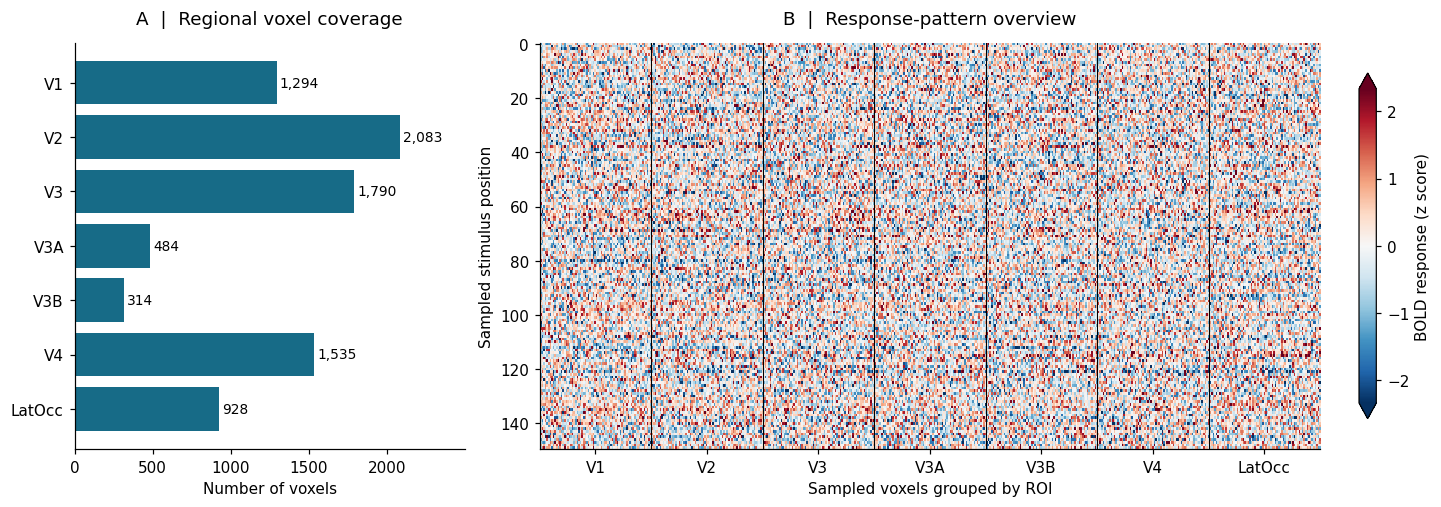

Heatmap scale: ±2.33; 2.0% of displayed values clipped.


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained',
                         gridspec_kw={'width_ratios': [1, 2]})
y = np.arange(len(ROI_ORDER))
axes[0].barh(y, region_table['n_voxels'], color=COLORS['training'])
axes[0].set_yticks(y, ROI_ORDER)
axes[0].invert_yaxis()
axes[0].set_xlim(0, region_table['n_voxels'].max() * 1.2)
for k, count in enumerate(region_table['n_voxels']):
    axes[0].text(count + 20, k, f'{count:,}', va='center', fontsize=9)
axes[0].set(xlabel='Number of voxels', title='A  |  Regional voxel coverage')

rng = np.random.default_rng(SEED)
columns, boundaries, centers = [], [0], []
for name in ROI_ORDER:
    candidates = np.flatnonzero(roi == roi_names.index(name))
    selected = np.sort(rng.choice(candidates, min(70, len(candidates)), replace=False))
    columns.extend(selected)
    centers.append((boundaries[-1] + len(columns) - 1) / 2)
    boundaries.append(len(columns))
rows = np.sort(rng.choice(len(responses), min(150, len(responses)), replace=False))
shown = responses[np.ix_(rows, columns)]
limit = float(np.quantile(np.abs(shown), .98))
limit = max(limit, np.finfo(float).eps)
im = axes[1].imshow(shown, aspect='auto', cmap='RdBu_r', vmin=-limit, vmax=limit,
                    interpolation='nearest')
for boundary in boundaries[1:-1]:
    axes[1].axvline(boundary - .5, color='black', linewidth=.7)
axes[1].set_xticks(centers, ROI_ORDER)
axes[1].set(xlabel='Sampled voxels grouped by ROI', ylabel='Sampled stimulus position',
            title='B  |  Response-pattern overview')
fig.colorbar(im, ax=axes[1], label='BOLD response (z score)', extend='both', shrink=.85)
save_figure(fig, '01_data_overview')
plt.show()
print(f'Heatmap scale: ±{limit:.2f}; {100 * np.mean(np.abs(shown) > limit):.1f}% of displayed values clipped.')


<a id="audit"></a>
## 2. Checking the supplied annotations

RSA depends on how similarity between images is defined. Before interpreting
the label-based model, we inspect the supplied annotations and their
relationship to the images.

The audit identifies two issues:

1. Some predicted classes and category labels do not agree with the image
   or with one another. For example, image 92 shows sliced fruit but has
   the predicted class “jellyfish.”
2. Secondary images 100–119 all share the annotation tuple
   `animal → acorn → acorn → Afghan hound`, despite showing varied content.

The galleries show targeted examples of these issues. They illustrate
specific mismatches rather than estimate the dataset-wide error rate.

The table also counts images using label strings that occur with multiple
parent labels. This measures inconsistency in the supplied label
relationships, not the number of incorrectly classified images.

We retain the original annotations for the main analysis and examine the
secondary repeated-label block separately in the sensitivity analysis.

In [25]:
def label_to_text(value):
    if isinstance(value, bytes):
        value = value.decode('utf-8')
    if value is None or (isinstance(value, (float, np.floating)) and np.isnan(value)):
        raise ValueError('Missing annotation; define a missing-label policy before analysis.')
    text = str(value).strip()
    if text.lower() in {'', 'nan', 'none', 'null'}:
        raise ValueError('Missing annotation; define a missing-label policy before analysis.')
    return text

def label_frame(array):
    return pd.DataFrame({name: [label_to_text(x) for x in array[k]]
        for k, name in enumerate(['level_1', 'level_2', 'level_3', 'predicted_class'])}
    ).rename_axis('stimulus_id')

train_labels = label_frame(labels)
secondary_labels = label_frame(heldout_labels)
audit_rows = []
for split, frame in [('training', train_labels), ('secondary', secondary_labels)]:
    row = {'split': split, 'n_images': len(frame),
           'unique_predicted_classes': frame.predicted_class.nunique()}
    for parent, child in [('level_1', 'level_2'), ('level_2', 'level_3')]:
        parent_counts = frame.groupby(child)[parent].nunique()
        multi = parent_counts[parent_counts > 1].index
        row[f'{child}_multi_parent_labels'] = len(multi)
        row[f'images_using_{child}_multi_parent_label'] = int(frame[child].isin(multi).sum())
    audit_rows.append(row)
audit_table = pd.DataFrame(audit_rows).set_index('split')
display(audit_table.T)

# Locate the maximal terminal run of identical complete annotation tuples.
# This is a diagnostic definition, not an automatic data-cleaning rule.
terminal_start = len(secondary_labels) - 1
last_tuple = secondary_labels.iloc[-1].to_numpy()
while terminal_start > 0 and np.array_equal(
        secondary_labels.iloc[terminal_start - 1].to_numpy(), last_tuple):
    terminal_start -= 1
terminal_ids = np.arange(terminal_start, len(secondary_labels))
print('Terminal repeated tuple:', ' → '.join(last_tuple))
print('Terminal block IDs:', terminal_ids.tolist())
print('Terminal block size:', len(terminal_ids))

# Apply the planned post-hoc sensitivity only if this exact audited pattern occurs.
EXPECTED_TERMINAL_TUPLE = ('animal', 'acorn', 'acorn', 'Afghan hound')
terminal_sensitivity_applicable = (
    tuple(last_tuple) == EXPECTED_TERMINAL_TUPLE and len(terminal_ids) > 1
    and terminal_start >= 3
)
print('Audited terminal-block sensitivity applicable:', terminal_sensitivity_applicable)


split,training,secondary
n_images,1750,120
unique_predicted_classes,529,84
level_2_multi_parent_labels,8,2
images_using_level_2_multi_parent_label,1360,37
level_3_multi_parent_labels,28,2
images_using_level_3_multi_parent_label,1234,8


Terminal repeated tuple: animal → acorn → acorn → Afghan hound
Terminal block IDs: [100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119]
Terminal block size: 20
Audited terminal-block sensitivity applicable: True


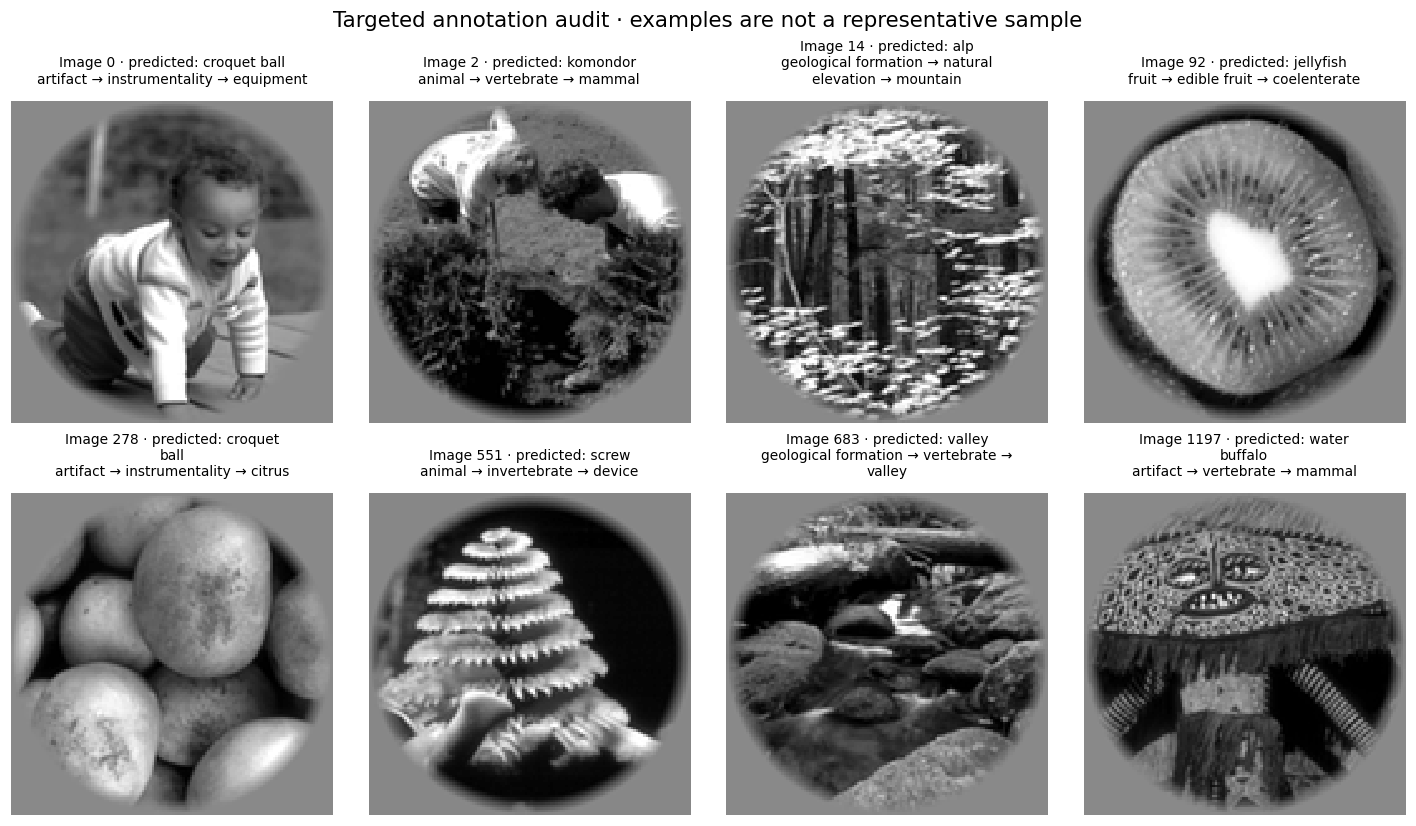

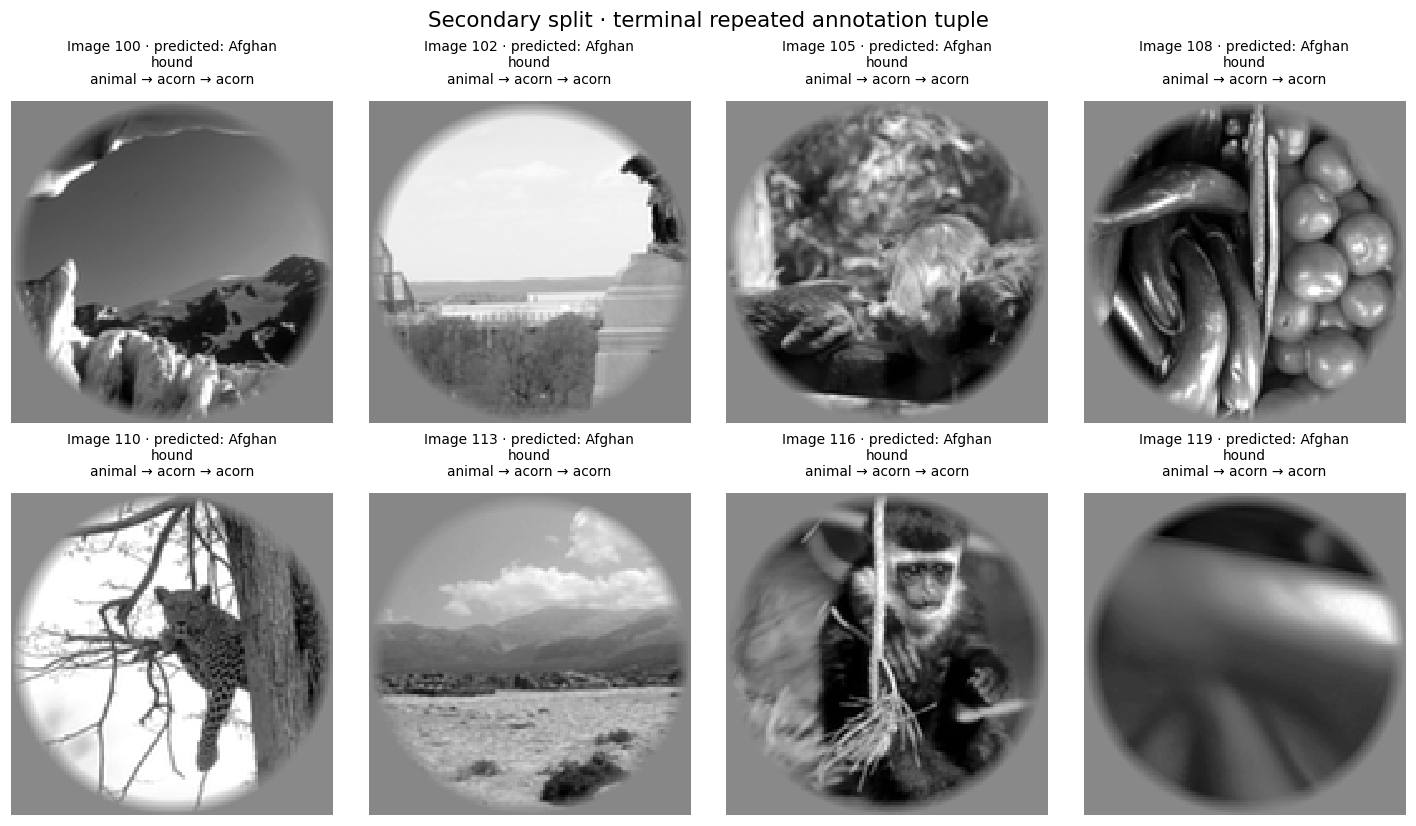

In [26]:
def annotation_gallery(images, frame, indices, title, filename):
    indices = [int(i) for i in indices if 0 <= i < len(frame)]
    if not indices:
        return
    ncols = 4
    fig, axes = plt.subplots(math.ceil(len(indices) / ncols), ncols,
        figsize=(13, 3.7 * math.ceil(len(indices) / ncols)), squeeze=False,
        layout='constrained')
    for ax in axes.flat:
        ax.set_axis_off()
    for ax, index in zip(axes.flat, indices):
        row = frame.iloc[index]
        ax.imshow(images[index], cmap='gray', interpolation='nearest')
        heading = f'Image {index} · predicted: {row.predicted_class}'
        annotation = ' → '.join(row[['level_1', 'level_2', 'level_3']])
        ax.set_title(textwrap.fill(heading, 34) + '\n' + textwrap.fill(annotation, 38), fontsize=9)
    fig.suptitle(title, fontsize=14)
    save_figure(fig, filename)
    plt.show()

annotation_gallery(stimuli, train_labels, [0, 2, 14, 92, 278, 551, 683, 1197],
    'Targeted annotation audit · examples are not a representative sample', '02_annotation_audit')
annotation_gallery(stimuli_heldout, secondary_labels,
    terminal_ids[np.linspace(0, len(terminal_ids)-1, min(8, len(terminal_ids)), dtype=int)],
    'Secondary split · terminal repeated annotation tuple', '03_terminal_annotation_block')


<a id="methods"></a>
## 3. Representational similarity analysis

RSA compares relationships between images in two representational spaces:
their supplied category labels and their measured brain-response patterns.

### Label similarity

For images \(i\) and \(j\), label similarity is the weighted fraction
of matching entries across the three supplied category levels:

$$
S_{ij} =
\frac{\sum_{\ell=1}^{3} w_\ell
\mathbf{1}[L_{\ell i}=L_{\ell j}]}
{\sum_{\ell=1}^{3} w_\ell},
\qquad w=(1,2,3).
$$

A pair sharing all three labels receives similarity 1; a pair sharing
none receives 0. This model retains the weights used in the earlier
analysis. Equal weights, individual levels, and exact predicted-class
matches are evaluated as alternative definitions.

Because the supplied levels are not consistently nested, the score is
interpreted as category-label overlap rather than a distance through
a verified semantic hierarchy.

### Neural similarity

Within each ROI, Pearson correlation measures similarity between two
images' response patterns across voxels. Repeating this calculation
for every image pair produces a neural similarity matrix.

### Comparing the representations

Spearman correlation compares the strict upper triangles of the label
and neural matrices. It asks whether image pairs with greater label
similarity also tend to have greater neural similarity.

Using the strict upper triangle excludes self-comparisons and counts
each image pair once. The 1,750-image analysis contains 1,530,375 pairs,
but these pairs are dependent because each image participates in many pairs.

### Permutation inference

We shuffle stimulus identities jointly across matrix rows and columns
to generate a null distribution. Each permutation is shared across ROIs,
and the maximum absolute null correlation provides correction across
the seven regional tests within each split.

This tests alignment between the supplied label model and neural
representations. Regional differences are reported descriptively;
a direct comparison between two regions would require a separate test.

In [27]:
def build_semantic_matrices(label_array, hierarchy_weights=HIERARCHY_WEIGHTS):
    """Build hierarchy-weighted, equal-weight, and DNN-label similarity matrices."""
    label_array = np.asarray(label_array)
    if label_array.ndim != 2 or label_array.shape[0] != 4:
        raise ValueError("Expected labels shaped (4, n_stimuli).")

    text_labels = np.array(
        [[label_to_text(value) for value in row] for row in label_array],
        dtype=object,
    )
    hierarchy = text_labels[:3].T  # (n_stimuli, 3 hierarchy levels)
    dnn_labels = text_labels[3]

    weights = np.asarray(hierarchy_weights, dtype=float)
    if weights.shape != (3,) or np.any(weights < 0) or weights.sum() == 0:
        raise ValueError("Use three non-negative weights with a positive sum.")

    matches = hierarchy[:, None, :] == hierarchy[None, :, :]
    weighted = np.einsum("ijk,k->ij", matches.astype(np.float32), weights)
    hierarchy_weighted = (weighted / weights.sum()).astype(np.float32)
    equal_weight = matches.mean(axis=2, dtype=np.float32)
    dnn_match = (dnn_labels[:, None] == dnn_labels[None, :]).astype(np.float32)

    for matrix in (hierarchy_weighted, equal_weight, dnn_match):
        matrix[:] = (matrix + matrix.T) / 2
        np.fill_diagonal(matrix, 1.0)
        if not np.isfinite(matrix).all():
            raise ValueError("Semantic similarity matrix contains non-finite values.")

    # A deeper label should ordinarily imply the same parent labels. Report
    # inconsistencies rather than silently assuming the labels form a perfect tree.
    same_level2 = hierarchy[:, None, 1] == hierarchy[None, :, 1]
    different_level1 = hierarchy[:, None, 0] != hierarchy[None, :, 0]
    level2_conflicts = int(np.count_nonzero(np.triu(same_level2 & different_level1, k=1)))

    same_level3 = hierarchy[:, None, 2] == hierarchy[None, :, 2]
    different_level2 = hierarchy[:, None, 1] != hierarchy[None, :, 1]
    level3_conflicts = int(np.count_nonzero(np.triu(same_level3 & different_level2, k=1)))

    diagnostics = {
        "n_stimuli": int(label_array.shape[1]),
        "unique_hierarchy_labels_by_level": [int(len(np.unique(hierarchy[:, i]))) for i in range(3)],
        "level2_parent_conflict_pairs": level2_conflicts,
        "level3_parent_conflict_pairs": level3_conflicts,
    }
    return hierarchy_weighted, equal_weight, dnn_match, diagnostics



semantic_similarity, semantic_equal, semantic_class, label_diagnostics = build_semantic_matrices(labels)
secondary_semantic, secondary_equal, secondary_class, secondary_diagnostics = build_semantic_matrices(heldout_labels)


In [28]:
def compute_roi_similarity_matrices(response_matrix, roi_codes, region_names):
    """Return stimulus-by-stimulus pattern-similarity matrices for non-empty ROIs."""
    response_matrix = np.asarray(response_matrix, dtype=np.float64)
    roi_codes = np.asarray(roi_codes, dtype=int)
    region_names = [label_to_text(name) for name in region_names]

    if response_matrix.ndim != 2:
        raise ValueError("Responses must have shape (n_stimuli, n_voxels).")
    if response_matrix.shape[1] != roi_codes.size:
        raise ValueError("ROI assignments must match the response voxel dimension.")
    if not np.isfinite(response_matrix).all():
        raise ValueError("Responses contain NaN or infinite values.")

    similarities = {}
    voxel_counts = {}
    for roi_code, region_name in enumerate(region_names):
        voxel_mask = roi_codes == roi_code
        n_voxels = int(voxel_mask.sum())
        if n_voxels == 0:
            print(f"Skipping {region_name}: no voxels in this archive.")
            continue

        region_responses = response_matrix[:, voxel_mask]
        pattern_sd = region_responses.std(axis=1)
        if np.any(pattern_sd <= np.finfo(float).eps):
            raise ValueError(
                f"At least one stimulus has a constant response pattern in {region_name}."
            )

        # Rows are stimuli, columns are voxels; rowvar=True makes each row a variable.
        similarity = np.corrcoef(region_responses)
        similarity = np.asarray((similarity + similarity.T) / 2, dtype=np.float32)
        np.fill_diagonal(similarity, 1.0)

        if not np.isfinite(similarity).all():
            raise ValueError(f"Neural similarity matrix for {region_name} is non-finite.")

        similarities[region_name] = similarity
        voxel_counts[region_name] = n_voxels
        print(f"{region_name:>8}: {n_voxels:>5,} voxels; matrix {similarity.shape}")

    return similarities, voxel_counts



train_neural_similarity, roi_voxel_counts = compute_roi_similarity_matrices(responses, roi, roi_names)
secondary_neural_similarity, secondary_voxel_counts = compute_roi_similarity_matrices(responses_heldout, roi, roi_names)
train_neural_similarity = {name: train_neural_similarity[name] for name in ROI_ORDER}
secondary_neural_similarity = {name: secondary_neural_similarity[name] for name in ROI_ORDER}


Skipping Other: no voxels in this archive.
      V1: 1,294 voxels; matrix (1750, 1750)
      V2: 2,083 voxels; matrix (1750, 1750)
      V3: 1,790 voxels; matrix (1750, 1750)
     V3A:   484 voxels; matrix (1750, 1750)
     V3B:   314 voxels; matrix (1750, 1750)
      V4: 1,535 voxels; matrix (1750, 1750)
  LatOcc:   928 voxels; matrix (1750, 1750)
Skipping Other: no voxels in this archive.
      V1: 1,294 voxels; matrix (120, 120)
      V2: 2,083 voxels; matrix (120, 120)
      V3: 1,790 voxels; matrix (120, 120)
     V3A:   484 voxels; matrix (120, 120)
     V3B:   314 voxels; matrix (120, 120)
      V4: 1,535 voxels; matrix (120, 120)
  LatOcc:   928 voxels; matrix (120, 120)


### Viewing the same images across representations

The next panels use the same deterministic image sample and category-sorted
ordering. Sorting changes only the display, not the analysis. Thin boundaries
mark the broad supplied label groups. Semantic similarity uses its own 0–1
scale; all neural panels share one symmetric scale, based on their pooled
99th percentile absolute off-diagonal similarity. Saturation is reported below.
Diagonals are masked. Apparent visual blocks are descriptive, not a test.


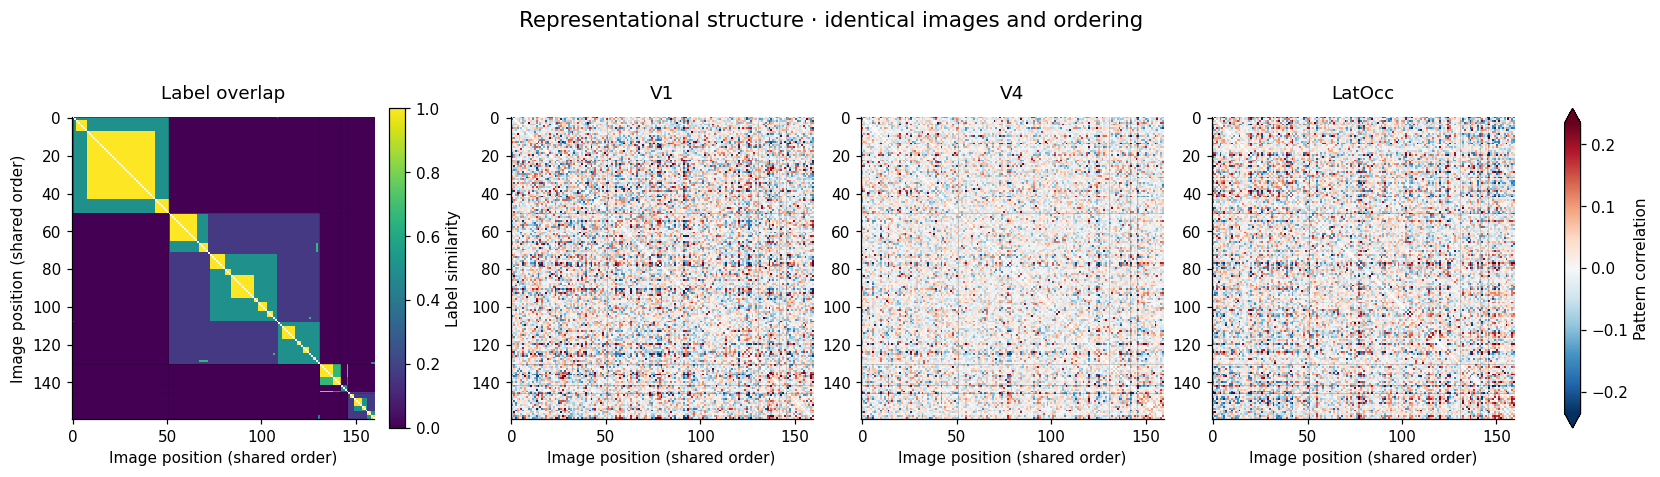

Neural display limits: ±0.234; 1% of pooled off-diagonal values clipped.


In [29]:
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(len(stimuli), min(160, len(stimuli)), replace=False)
ordered = train_labels.loc[sample_ids].sort_values(['level_1', 'level_2', 'level_3', 'predicted_class'], kind='stable')
plot_ids = ordered.index.to_numpy()
groups = ordered.level_1.to_numpy()
breaks = np.flatnonzero(groups[1:] != groups[:-1]) + 1
mats = [semantic_similarity] + [train_neural_similarity[r] for r in ['V1', 'V4', 'LatOcc']]
shown = [np.array(m[np.ix_(plot_ids, plot_ids)], dtype=float) for m in mats]
for m in shown:
    np.fill_diagonal(m, np.nan)
limit = float(np.nanquantile(np.abs(np.stack(shown[1:])), .99))
limit = max(limit, 1e-6)
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), layout='constrained')
for k, (ax, matrix, title) in enumerate(zip(axes, shown, ['Label overlap', 'V1', 'V4', 'LatOcc'])):
    im = ax.imshow(matrix, cmap='viridis' if k == 0 else 'RdBu_r',
        vmin=0 if k == 0 else -limit, vmax=1 if k == 0 else limit, interpolation='nearest')
    for boundary in breaks:
        ax.axhline(boundary-.5, color='black', alpha=.25, linewidth=.4)
        ax.axvline(boundary-.5, color='black', alpha=.25, linewidth=.4)
    ax.set(title=title, xlabel='Image position (shared order)')
    if k == 0:
        ax.set_ylabel('Image position (shared order)')
        fig.colorbar(im, ax=ax, shrink=.7, label='Label similarity')
fig.colorbar(im, ax=list(axes[1:]), shrink=.7, label='Pattern correlation', extend='both')
fig.suptitle('Representational structure · identical images and ordering', fontsize=14)
save_figure(fig, '04_coordinated_similarity_matrices')
plt.show()
print(f'Neural display limits: ±{limit:.3f}; 1% of pooled off-diagonal values clipped.')


In [30]:
def run_rsa_permutation_test(
    semantic_matrix,
    neural_matrices,
    voxel_counts,
    n_permutations=1999,
    random_seed=20261021,
    progress_label="Stimulus permutations",
):
    """Spearman RSA with stimulus-label permutation and max-statistic ROI correction."""
    semantic_matrix = np.asarray(semantic_matrix, dtype=np.float32)
    n_stimuli = semantic_matrix.shape[0]
    if semantic_matrix.shape != (n_stimuli, n_stimuli):
        raise ValueError("Semantic matrix must be square.")
    if any(matrix.shape != semantic_matrix.shape for matrix in neural_matrices.values()):
        raise ValueError("All neural matrices must match the semantic matrix shape.")
    if n_permutations < 99:
        raise ValueError("Use at least 99 permutations; 1,999 or more is preferable for final results.")

    upper_i, upper_j = np.triu_indices(n_stimuli, k=1)
    semantic_upper = semantic_matrix[upper_i, upper_j].astype(np.float64)
    semantic_ranks = rankdata(semantic_upper, method="average").astype(np.float64)
    semantic_ranks -= semantic_ranks.mean()
    semantic_norm = np.linalg.norm(semantic_ranks)
    if semantic_norm == 0:
        raise ValueError("Semantic matrix has no variation in its off-diagonal values.")

    region_names = list(neural_matrices.keys())
    observed_rho = {}
    rank_matrices = {}
    neural_rank_norms = {}

    for region_name in region_names:
        neural_upper = np.asarray(neural_matrices[region_name][upper_i, upper_j], dtype=np.float64)
        neural_ranks = rankdata(neural_upper, method="average").astype(np.float64)
        neural_ranks -= neural_ranks.mean()
        neural_norm = np.linalg.norm(neural_ranks)
        if neural_norm == 0:
            raise ValueError(f"Neural similarity matrix for {region_name} has no variation.")

        observed_rho[region_name] = float(
            np.dot(semantic_ranks, neural_ranks) / (semantic_norm * neural_norm)
        )
        neural_rank_norms[region_name] = neural_norm

        # Store centered ranks in a symmetric matrix. Permuting its row and column
        # identities changes pair assignments without recomputing the ranks.
        rank_matrix = np.zeros((n_stimuli, n_stimuli), dtype=np.float32)
        centered_ranks = neural_ranks.astype(np.float32)
        rank_matrix[upper_i, upper_j] = centered_ranks
        rank_matrix[upper_j, upper_i] = centered_ranks
        rank_matrices[region_name] = rank_matrix

    rng_perm = np.random.default_rng(random_seed)
    null_rhos = np.empty((n_permutations, len(region_names)), dtype=np.float32)

    for permutation_index in tqdm(range(n_permutations), desc=progress_label):
        permutation = rng_perm.permutation(n_stimuli)
        permuted_i = permutation[upper_i]
        permuted_j = permutation[upper_j]

        for region_index, region_name in enumerate(region_names):
            permuted_neural_ranks = rank_matrices[region_name][permuted_i, permuted_j]
            null_rhos[permutation_index, region_index] = (
                np.dot(semantic_ranks, permuted_neural_ranks)
                / (semantic_norm * neural_rank_norms[region_name])
            )

    observed_values = np.array([observed_rho[name] for name in region_names])
    p_uncorrected = (
        1 + (np.abs(null_rhos) >= np.abs(observed_values)[None, :]).sum(axis=0)
    ) / (n_permutations + 1)

    # The same stimulus permutation is used across ROIs, preserving their dependence.
    max_abs_null = np.max(np.abs(null_rhos), axis=1)
    p_fwer = (
        1 + (max_abs_null[:, None] >= np.abs(observed_values)[None, :]).sum(axis=0)
    ) / (n_permutations + 1)

    results = pd.DataFrame({
        "roi": region_names,
        "n_voxels": [int(voxel_counts[name]) for name in region_names],
        "n_stimuli": n_stimuli,
        "n_pairs": len(upper_i),
        "spearman_rho": observed_values,
        "p_permutation_two_sided": p_uncorrected,
        "p_fwer_max_statistic": p_fwer,
        "n_permutations": n_permutations,
        "permutation_seed": random_seed,
    })
    return results, null_rhos


### Numerical verification and reproducible caching

A small synthetic check compares the optimized rank calculation with SciPy's
Spearman correlation, including an explicitly permuted matrix. Cached results are reused when the recorded input hashes, software versions, settings, and analysis-code signature match. Download hashes identify the bytes used; without a
trusted reference digest they do not independently authenticate the files.


In [31]:
import types

rng = np.random.default_rng(123)
tiny_labels = np.array([['a','a','b','b','c','c'], ['x','y','x','y','x','y'],
                       ['p','p','q','r','q','r'], ['a','b','c','d','e','f']])
tiny_semantic = build_semantic_matrices(tiny_labels)[0]
tiny_neural = np.corrcoef(rng.normal(size=(6, 12))).astype(np.float32)
tiny_results, tiny_null = run_rsa_permutation_test(tiny_semantic, {'demo': tiny_neural},
    {'demo': 12}, n_permutations=99, random_seed=123, progress_label='Numerical check')
u = np.triu_indices(6, 1)
expected = spearmanr(tiny_semantic[u], tiny_neural[u]).statistic
assert np.isclose(tiny_results.spearman_rho.iloc[0], expected, atol=1e-7)
permutation = np.random.default_rng(123).permutation(6)
expected_null = spearmanr(tiny_semantic[u], tiny_neural[np.ix_(permutation, permutation)][u]).statistic
assert np.isclose(tiny_null[0, 0], expected_null, atol=1e-7)
print('Observed and permuted RSA calculations agree with direct Spearman correlation.')

PACKAGE_VERSIONS = {p: importlib.metadata.version(p) for p in
                    ['numpy', 'scipy', 'pandas', 'matplotlib', 'requests', 'tqdm']}
# Ignore runtime cell filenames and line numbers so a rerun keeps the same cache key.
def stable_code_signature(code_object):
    constants = [stable_code_signature(x) if isinstance(x, types.CodeType) else repr(x)
                 for x in code_object.co_consts]
    return {'bytecode': code_object.co_code.hex(), 'names': code_object.co_names,
            'constants': constants}
METHOD_HASH = hashlib.sha256(json.dumps([
    stable_code_signature(fn.__code__) for fn in
    [build_semantic_matrices, compute_roi_similarity_matrices, run_rsa_permutation_test]
], sort_keys=True).encode()).hexdigest()

def cached_inference(semantic, neural, counts, split, n_permutations, seed):
    settings = {'inputs': INPUT_HASHES, 'versions': PACKAGE_VERSIONS,
        'method': METHOD_HASH, 'split': split, 'weights': HIERARCHY_WEIGHTS.tolist(),
        'n_permutations': n_permutations, 'seed': seed, 'roi_order': list(neural)}
    key = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:20]
    table_path = CACHE_DIR / f'{split}_{key}.csv'
    null_path = CACHE_DIR / f'{split}_{key}.npy'
    meta_path = CACHE_DIR / f'{split}_{key}.json'
    if table_path.exists() and null_path.exists() and meta_path.exists():
        print(f'Reusing matching cache: {split}')
        return pd.read_csv(table_path), np.load(null_path, allow_pickle=False)
    start = time.perf_counter()
    table, null = run_rsa_permutation_test(semantic, neural, counts,
        n_permutations=n_permutations, random_seed=seed, progress_label=split)
    table.to_csv(table_path, index=False)
    np.save(null_path, null, allow_pickle=False)
    settings['elapsed_seconds'] = time.perf_counter() - start
    meta_path.write_text(json.dumps(settings, indent=2))
    print(f'{split}: {settings["elapsed_seconds"] / 60:.1f} minutes')
    return table, null


Numerical check:   0%|          | 0/99 [00:00<?, ?it/s]

Observed and permuted RSA calculations agree with direct Spearman correlation.


<a id="results"></a>
## 4. Results across visual regions

In the training set, the strongest label–neural correspondence occurs
in LatOcc (ρ = 0.0382), followed by V3B (ρ = 0.0227) and V4 (ρ = 0.0177).
V1 shows little correspondence with this label model (ρ = 0.0020).

The effect sizes are small. Under the seven-ROI permutation correction,
six training regions have p < 0.05; V1 has corrected p = 0.073.

The secondary set gives larger correlations and a different regional
ordering, with the largest estimate in V3A (ρ = 0.0807). The repeated
annotation block is examined separately below.

In the figure, points farther right indicate stronger correspondence.
Points show estimates without confidence intervals. Corrected p-values
appear in the tables.

With 1,999 training permutations, the minimum attainable p-value is
0.0005. Several regions reach this resolution limit.

Reusing matching cache: training
Reusing matching cache: secondary_all


**Training**

,n_stimuli,n_voxels,spearman_rho,p_permutation_two_sided,p_fwer_max_statistic
roi,,,,,
V1,1750,1294,0.00195,0.0200,0.0730
V2,1750,2083,0.00425,0.0010,0.0015
V3,1750,1790,0.00660,0.0005,0.0005
V3A,1750,484,0.01210,0.0005,0.0005
V3B,1750,314,0.02269,0.0005,0.0005
V4,1750,1535,0.01771,0.0005,0.0005
LatOcc,1750,928,0.03816,0.0005,0.0005


**Secondary, all supplied images**

,n_stimuli,n_voxels,spearman_rho,p_permutation_two_sided,p_fwer_max_statistic
roi,,,,,
V1,120,1294,0.03849,0.0100,0.0794
V2,120,2083,0.04655,0.0044,0.0304
V3,120,1790,0.05614,0.0016,0.0108
V3A,120,484,0.08069,0.0002,0.0004
V3B,120,314,0.06479,0.0004,0.0040
V4,120,1535,0.03154,0.0550,0.1888
LatOcc,120,928,0.05106,0.0114,0.0180


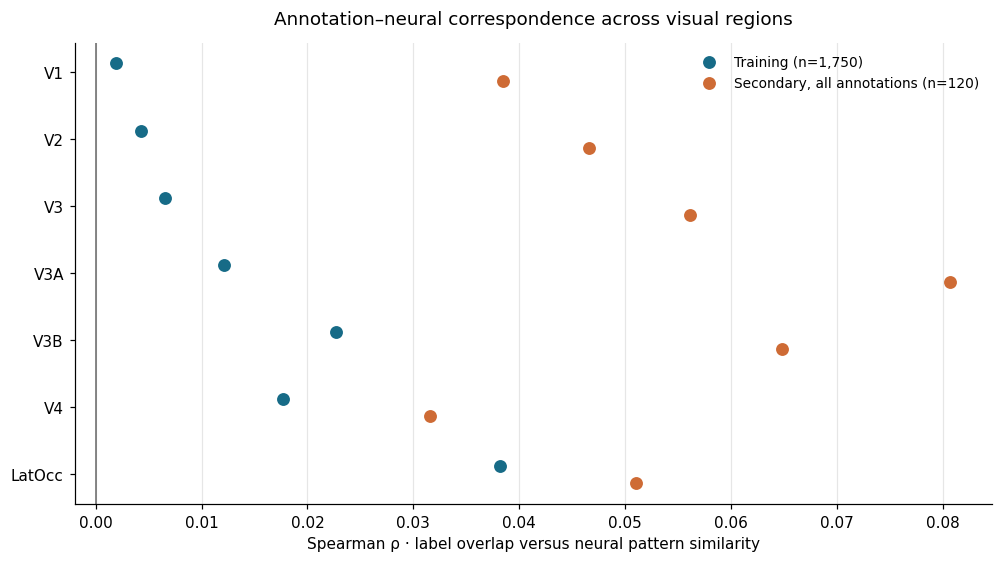

In [32]:
train_results, train_null = cached_inference(semantic_similarity, train_neural_similarity,
    roi_voxel_counts, 'training', N_PERMUTATIONS_TRAIN, 20261021)
secondary_results, secondary_null = cached_inference(secondary_semantic, secondary_neural_similarity,
    secondary_voxel_counts, 'secondary_all', N_PERMUTATIONS_SECONDARY, 20261022)

for name, results in [('Training', train_results), ('Secondary, all supplied images', secondary_results)]:
    display(Markdown(f'**{name}**'))
    display(results.set_index('roi').reindex(ROI_ORDER)[
        ['n_stimuli', 'n_voxels', 'spearman_rho', 'p_permutation_two_sided', 'p_fwer_max_statistic']
    ].round(5))

fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
y = np.arange(len(ROI_ORDER))
for results, offset, color, label in [
    (train_results, -.13, COLORS['training'], f'Training (n={len(stimuli):,})'),
    (secondary_results, .13, COLORS['secondary'], f'Secondary, all annotations (n={len(stimuli_heldout)})')]:
    values = results.set_index('roi').reindex(ROI_ORDER).spearman_rho.to_numpy()
    ax.scatter(values, y + offset, color=color, s=55, label=label, zorder=3)
ax.set_yticks(y, ROI_ORDER)
ax.invert_yaxis()
ax.axvline(0, color='0.4', linewidth=1)
ax.grid(axis='x', color='.9')
ax.set(xlabel='Spearman ρ · label overlap versus neural pattern similarity',
       title='Annotation–neural correspondence across visual regions')
ax.legend(loc='best', frameon=False, fontsize=9)
save_figure(fig, '05_rsa_across_splits')
plt.show()


In [33]:
t = train_results.set_index('roi')
s = secondary_results.set_index('roi')
display(Markdown(
    f'**Result summary.** The largest training correlation is in **{t.spearman_rho.idxmax()}** '
    f'(ρ = {t.spearman_rho.max():.4f}). Training LatOcc and V1 correlations are '
    f'{t.loc["LatOcc", "spearman_rho"]:.4f} and {t.loc["V1", "spearman_rho"]:.4f}. '
    f'The largest secondary-split correlation is in **{s.spearman_rho.idxmax()}** '
    f'(ρ = {s.spearman_rho.max():.4f}). These are descriptive comparisons. '
    'The secondary estimates use the anomalous annotation block and must be read '
    'alongside the sensitivity analysis below.'
))


**Result summary.** The largest training correlation is in **LatOcc** (ρ = 0.0382). Training LatOcc and V1 correlations are 0.0382 and 0.0020. The largest secondary-split correlation is in **V3A** (ρ = 0.0807). These are descriptive comparisons. The secondary estimates use the anomalous annotation block and must be read alongside the sensitivity analysis below.

<a id="robustness"></a>
## 5. Robustness to annotation-model choices

We compare the weighted model with equal weights, exact predicted-class
matching, and each supplied label level separately.

Weighted and equal-weight results are almost identical: the largest
absolute regional difference is 0.000068. Thus, the training pattern
does not materially depend on this particular choice of weights.

LatOcc has the highest correlation under every model shown here.
Exact predicted-class matching produces a smaller LatOcc correlation
(ρ = 0.0146) than the weighted category model (ρ = 0.0382).

These comparisons describe sensitivity to the annotation model.
They are not additional corrected hypothesis tests.

model,Weighted rows,Equal weights,Predicted class,Supplied label level 1,Supplied label level 2,Supplied label level 3
roi,,,,,,
V1,0.00195,0.00189,0.00537,0.00123,0.00222,0.00295
V2,0.00425,0.00418,0.00582,0.00311,0.00454,0.00552
V3,0.00660,0.00657,0.00562,0.00570,0.00601,0.00674
V3A,0.01210,0.01213,0.00414,0.01114,0.01114,0.00960
V3B,0.02269,0.02267,0.01138,0.02040,0.02077,0.01817
V4,0.01771,0.01765,0.01062,0.01496,0.01725,0.01800
LatOcc,0.03816,0.03809,0.01462,0.03278,0.03661,0.03773


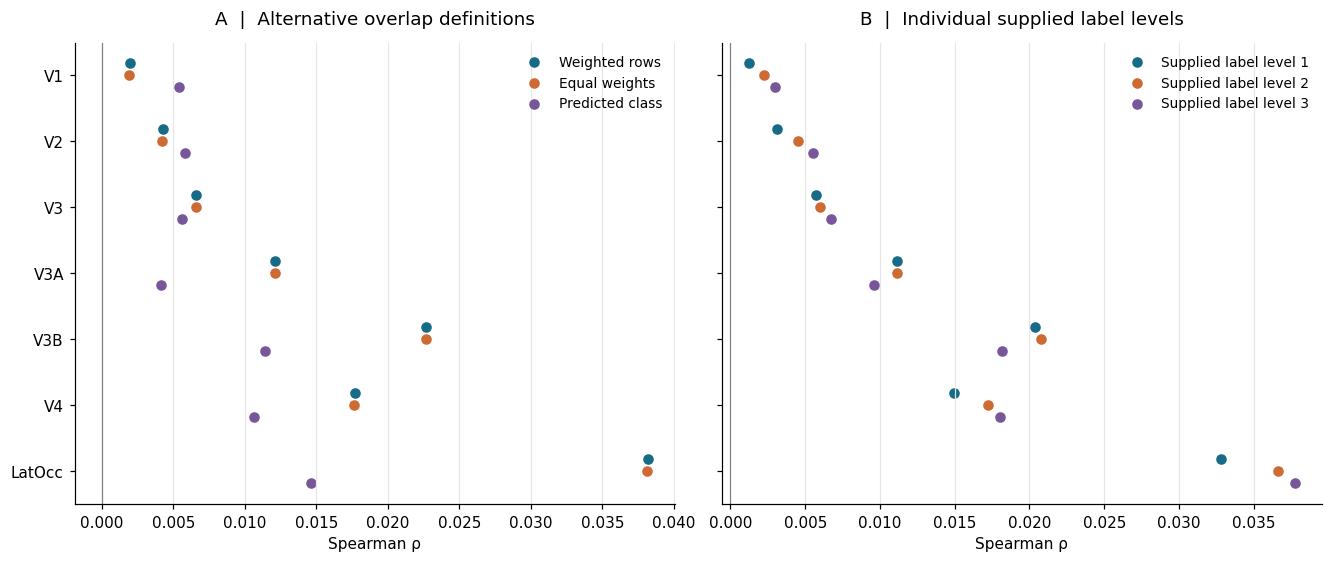

Largest absolute weighted–equal difference: 0.000068


In [34]:
def descriptive_rsa(model, neural, name):
    upper = np.triu_indices(len(model), 1)
    semantic_ranks = rankdata(model[upper], method='average')
    semantic_ranks -= semantic_ranks.mean()
    semantic_norm = np.linalg.norm(semantic_ranks)
    if semantic_norm == 0:
        raise ValueError(f'Constant off-diagonal model: {name}')
    rows = []
    for region, matrix in neural.items():
        ranks = rankdata(matrix[upper], method='average')
        ranks -= ranks.mean()
        denom = semantic_norm * np.linalg.norm(ranks)
        if denom == 0:
            raise ValueError(f'Constant neural similarity: {region}')
        rows.append({'model': name, 'roi': region,
            'spearman_rho': float(np.dot(semantic_ranks, ranks) / denom)})
    return pd.DataFrame(rows)

model_results = [train_results[['roi', 'spearman_rho']].assign(model='Weighted rows')]
for name, model in [('Equal weights', semantic_equal), ('Predicted class', semantic_class)]:
    model_results.append(descriptive_rsa(model, train_neural_similarity, name))
for k in range(3):
    row = train_labels.iloc[:, k].to_numpy()
    model_results.append(descriptive_rsa((row[:, None] == row[None, :]).astype(np.float32),
                                        train_neural_similarity, f'Supplied label level {k+1}'))
sensitivity_results = pd.concat(model_results, ignore_index=True)
model_order = [
    'Weighted rows',
    'Equal weights',
    'Predicted class',
    'Supplied label level 1',
    'Supplied label level 2',
    'Supplied label level 3',
]
wide = sensitivity_results.pivot(index='roi', columns='model', values='spearman_rho').reindex(ROI_ORDER)
display(wide[model_order].round(5))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout='constrained')
for ax, names in zip(axes, [model_order[:3], model_order[3:]]):
    for j, (name, color) in enumerate(zip(names, ['#176B87', '#CE6B35', '#77579A'])):
        ax.scatter(wide[name], np.arange(7) + (j-1)*.18, s=35, color=color, label=name)
    ax.axvline(0, color='.5', linewidth=.8)
    ax.grid(axis='x', color='.9')
    ax.set_xlabel('Spearman ρ')
    ax.legend(frameon=False, fontsize=9)
axes[0].set_yticks(np.arange(7), ROI_ORDER)
axes[0].invert_yaxis()
axes[0].set_title('A  |  Alternative overlap definitions')
axes[1].set_title('B  |  Individual supplied label levels')
save_figure(fig, '06_annotation_model_sensitivity')
plt.show()
print('Largest absolute weighted–equal difference:',
      f'{(wide["Weighted rows"] - wide["Equal weights"]).abs().max():.6f}')


### How the annotation anomaly affects the results

The final 20 secondary images have identical supplied annotations despite
showing different content. Consequently, the label model assigns maximum
similarity to all 190 image pairs within this block, regardless of their
actual semantic relationship. Their similarities to images outside the
block are also determined by these questionable annotations.

This directly affects the target matrix used by RSA. The analysis therefore
measures correspondence with an annotation structure that partly reflects
a data-quality problem rather than meaningful image categories.

Excluding the block reduces correlations in every region:

| Region | All 120 images | Excluding the final 20 |
|---|---:|---:|
| V1 | 0.03849 | 0.00108 |
| V2 | 0.04655 | 0.00983 |
| V3 | 0.05614 | 0.02403 |
| V3A | 0.08069 | 0.03573 |
| V3B | 0.06479 | 0.03645 |
| V4 | 0.03154 | 0.00373 |
| LatOcc | 0.05106 | 0.02565 |

The substantially larger full-sample estimates cannot be confidently
interpreted as stronger semantic–neural correspondence. They are sensitive
to the inclusion of a block whose annotations are not credible descriptions
of the images.

Exclusion changes both the image sample and its annotation structure.
Therefore, this comparison does not isolate the amount of bias caused
by incorrect labels, and the remaining 100 images are not automatically
verified or error-free.

Both analyses are retained. Connecting lines in the figure show changes
in estimates, not confidence intervals. The full-sample permutation
p-values do not apply to the reduced sample.

,all_images_rho,terminal_block_excluded_rho,difference
roi,,,
V1,0.03849,0.00108,-0.03741
V2,0.04655,0.00983,-0.03672
V3,0.05614,0.02403,-0.03211
V3A,0.08069,0.03573,-0.04496
V3B,0.06479,0.03645,-0.02835
V4,0.03154,0.00373,-0.02780
LatOcc,0.05106,0.02565,-0.02541


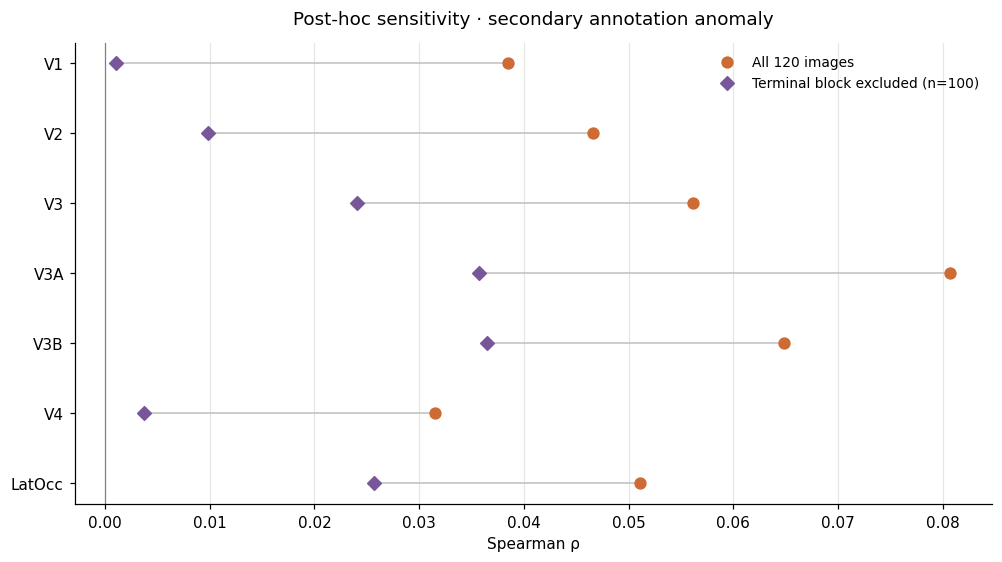

Excluding IDs **100–119** changes the stimulus sample from 120 to 100 images. The largest absolute ROI change is **0.0450**. This quantifies sensitivity to the audited block; it does not identify the true semantic effect.

In [35]:
terminal_sensitivity_results = pd.DataFrame()
if terminal_sensitivity_applicable:
    keep = np.arange(terminal_start)
    reduced_semantic = secondary_semantic[np.ix_(keep, keep)]
    reduced_neural = {name: matrix[np.ix_(keep, keep)] for name, matrix in secondary_neural_similarity.items()}
    terminal_sensitivity_results = descriptive_rsa(reduced_semantic, reduced_neural, 'Terminal block excluded')
    comparison = secondary_results[['roi', 'spearman_rho']].rename(columns={'spearman_rho': 'all_images_rho'})
    comparison = comparison.merge(terminal_sensitivity_results[['roi', 'spearman_rho']], on='roi', validate='one_to_one')
    comparison = comparison.rename(columns={'spearman_rho': 'terminal_block_excluded_rho'}).set_index('roi').reindex(ROI_ORDER)
    comparison['difference'] = comparison.terminal_block_excluded_rho - comparison.all_images_rho
    display(comparison.round(5))
    fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
    for k, name in enumerate(ROI_ORDER):
        ax.plot([comparison.loc[name, 'all_images_rho'], comparison.loc[name, 'terminal_block_excluded_rho']],
                [k, k], color='.75', linewidth=1)
    ax.scatter(comparison.all_images_rho, np.arange(7), color=COLORS['secondary'],
               label=f'All {len(secondary_labels)} images', s=50, zorder=3)
    ax.scatter(comparison.terminal_block_excluded_rho, np.arange(7), color=COLORS['sensitivity'],
               label=f'Terminal block excluded (n={len(keep)})', marker='D', s=40, zorder=3)
    ax.set_yticks(np.arange(7), ROI_ORDER)
    ax.invert_yaxis()
    ax.axvline(0, color='.5', linewidth=.8)
    ax.grid(axis='x', color='.9')
    ax.set(xlabel='Spearman ρ', title='Post-hoc sensitivity · secondary annotation anomaly')
    ax.legend(frameon=False, fontsize=9)
    save_figure(fig, '07_terminal_block_sensitivity')
    plt.show()
    display(Markdown(f'Excluding IDs **{terminal_start}–{len(secondary_labels)-1}** changes the stimulus sample '
        f'from {len(secondary_labels)} to {len(keep)} images. The largest absolute ROI change is '
        f'**{comparison["difference"].abs().max():.4f}**. '
        'This quantifies sensitivity to the audited block; it does not identify the true semantic effect.'))
else:
    print('The audited terminal tuple was not detected; no automatic exclusion performed.')


<a id="discussion"></a>
## 6. Discussion

The 1,750-image analysis finds small positive correspondence between
supplied category-label similarity and fMRI response-pattern similarity.
The largest correlation occurs in LatOcc (ρ = 0.0382), compared with
ρ = 0.0020 in V1. Weighted and equal-weight overlap produce nearly
identical estimates.

### How annotation quality limits the conclusions

The label annotations define the semantic model against which neural
representations are compared. Incorrect labels can make unrelated images
appear similar, make related images appear different, and distort the
relative ordering of image-pair similarities.

These errors can weaken, inflate, or otherwise change RSA correlations.
Their effect is not necessarily a simple reduction in signal.

The training gallery reveals annotation mismatches, but the audit does
not establish their overall frequency or quantify their effect on the
training correlations. Consequently, the LatOcc result is evidence of
correspondence with the supplied label model; its magnitude cannot be
treated as an unbiased estimate of correspondence with accurate semantic
categories.

The secondary split contains a more conspicuous anomaly: its final
20 images share an identical annotation tuple despite varied visual
content. Removing that block lowers correlations across all seven regions.
For example, V3A decreases from 0.0807 to 0.0357, and LatOcc decreases
from 0.0511 to 0.0257.

This sensitivity prevents the larger full-secondary-split correlations
from serving as convincing confirmation of stronger semantic correspondence.
The reduced-sample analysis is informative, but it does not repair the
annotations or establish a clean validation dataset.

Permutation significance does not resolve this issue. A small p-value
indicates alignment with the supplied model under the permutation procedure;
it does not establish that the model's labels are accurate.

### What the project establishes

The project implements a reproducible RSA workflow across seven visual
regions, examines alternative label-model definitions, and demonstrates
how annotation quality can materially affect interpretation.

The observed training pattern is stable under the two weighting schemes
tested. The stronger biological interpretation—how accurately these
regions represent semantic relationships—requires a better-established
semantic target.

Additional considerations include unequal voxel counts and response
reliability across regions, possible low-level visual confounds, and
unresolved participant provenance in the distributed archive. Regional
differences are descriptive; a direct inferential comparison between
regions has not been performed.

### Next scientific steps

The priority is to investigate the annotation-generation history and
establish a documented, quality-checked semantic model. Any corrected or
replacement annotations should be versioned separately, with the original
results retained for comparison.

Subsequent extensions could compare semantic and low-level visual models
and examine participant-specific results if the necessary data become
available.

### Project origins and subsequent development

This work originated as a team project in the Neuromatch Academy
Computational Neuroscience course. The original team consisted of me,
Fereshteh Fathi, Erfaneh Hosseini, and Paniz Kheyri.

The course project was supported by project TA Dr. Mahdie Soltaninejad,
project mentor Dr. Ladan Shahshahani, and pod TA Dr. Reza Seifooripour.

Following the course, I independently developed this revised version,
building on the team's original work. The revision expands the annotation
audit, adds sensitivity analyses, improves the visualizations and research
narrative, and strengthens reproducibility.

AI assistance was used during the revision for code and writing support.
The distinction between the original collaborative project and this
subsequent individual revision is maintained here to credit both stages
of the work.

<a id="references"></a>
## 7. References

- Kay, K. N., Naselaris, T., Prenger, R. J., & Gallant, J. L. (2008).
  *Identifying natural images from human brain activity.* Nature, 452, 352–355.
  [doi:10.1038/nature06713](https://doi.org/10.1038/nature06713)
- Kriegeskorte, N., Mur, M., & Bandettini, P. A. (2008).
  *Representational similarity analysis—connecting the branches of systems neuroscience.*
  Frontiers in Systems Neuroscience, 2, 4.
  [doi:10.3389/neuro.06.004.2008](https://doi.org/10.3389/neuro.06.004.2008)
- Nili, H., et al. (2014). *A toolbox for representational similarity analysis.*
  PLOS Computational Biology, 10(4), e1003553.
  [doi:10.1371/journal.pcbi.1003553](https://doi.org/10.1371/journal.pcbi.1003553)
- Neuromatch Academy. [Kay-image data loading notebook](https://github.com/NeuromatchAcademy/course-content/blob/main/projects/fMRI/load_kay_images.ipynb).
  Source of the distributed files and array descriptions.

## 8. Export reproducible results

The export contains figures, tables, input hashes, analysis settings, and package
versions. Raw images and fMRI arrays are not copied into the result bundle.
The cache is also excluded from the shareable ZIP.


In [36]:
import zipfile

exports = {'rsa_training_results': train_results, 'rsa_secondary_results': secondary_results,
           'annotation_model_sensitivity': sensitivity_results,
           'annotation_audit': audit_table.reset_index()}
if not terminal_sensitivity_results.empty:
    exports['terminal_block_sensitivity'] = comparison.reset_index()
for name, table in exports.items():
    table.to_csv(OUTPUT_DIR / f'{name}.csv', index=False)

metadata = {
    'project': 'Semantic-label correspondence in human visual cortex',
    'analysis_status': 'exploratory portfolio revision',
    'python': platform.python_version(), 'packages': PACKAGE_VERSIONS,
    'input_urls': FILES, 'input_sha256': INPUT_HASHES, 'method_hash': METHOD_HASH,
    'n_training': len(stimuli), 'n_secondary': len(stimuli_heldout),
    'roi_voxel_counts': {k: int(v) for k, v in roi_voxel_counts.items()},
    'semantic_model': 'weighted exact overlap of supplied annotation rows 0–2',
    'weights': HIERARCHY_WEIGHTS.tolist(), 'weight_selection_history': 'not established',
    'neural_metric': 'Pearson correlation across ROI voxels',
    'rsa_metric': 'Spearman correlation of strict upper triangles; average tie ranks',
    'inference': 'two-sided stimulus-identity permutations; shared across ROIs',
    'correction': 'maximum absolute null statistic across seven ROIs separately per split',
    'permutations': {'training': N_PERMUTATIONS_TRAIN, 'secondary': N_PERMUTATIONS_SECONDARY},
    'seeds': {'figures': SEED, 'training': 20261021, 'secondary': 20261022},
    'participant_provenance': 'unresolved in distributed archive',
    'secondary_is_confirmatory': False,
    'annotations_modified': False,
    'posthoc_terminal_sensitivity_applied': bool(terminal_sensitivity_applicable),
    'posthoc_excluded_ids': terminal_ids.tolist() if terminal_sensitivity_applicable else [],
    'posthoc_exclusion_rule': 'maximal terminal run of animal / acorn / acorn / Afghan hound',
}
(OUTPUT_DIR / 'analysis_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
archive_path = OUTPUT_DIR / 'fmri_rsa_results.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(OUTPUT_DIR.glob('*.csv')):
        archive.write(path, path.name)
    archive.write(OUTPUT_DIR / 'analysis_metadata.json', 'analysis_metadata.json')
    for path in sorted(FIGURES_DIR.glob('*')):
        if path.is_file():
            archive.write(path, Path('figures') / path.name)
print('Saved result bundle:', archive_path)


Saved result bundle: /content/fmri_rsa_outputs/fmri_rsa_results.zip
